<a href="https://colab.research.google.com/github/JFish72/CSC-349-Machine-Learning-/blob/main/HW8/diabetes_neural_net.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Task One:**
*   Using the same CSV file from Assignment 5, I loaded the data into a pandas DataFrame. The CSV file once again has the same issue of lacking column titles, so I had to manually add them in order to make the display of the data usable. I then displayed the dataset's characteristics through its dimensions, summary statistics, and missing values. This is one of the most standard and important steps in the ML process.
*   Since I have already examined this data from our past homework, I know that zero values are used to represent an unrecorded piece of medical data. Nevertheless, to demonstrate the full cleaning process of data I check for missing values and then replace the false zero values with NaN to make the use of a median imputer function properly (SimpleImputer).
*   I then separate the data into an 80/20 train-test split as well as create a validation set that will be used later in Task 4. I then use a StandardScaler to standardize the numerical features for my future neural networks. As usual, the imputation and scaling are only done on the training data to prevent leakage. To demonstrate the changes made by scaling, boxplots of the data before and after scaling are placed side-by-side.  





In [26]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense, Dropout, BatchNormalization
from tensorflow.keras.callbacks import EarlyStopping

tf.keras.utils.set_random_seed(42)

columns = ["Pregnancies", "Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI", "DPF", "Age", "Outcome"]
#I made DiabetesPedigreeFunction an abbreviation for it to better fit on my boxplots.

df = pd.read_csv("pima-indians-diabetes.csv", header = None, names = columns)

display(df.head())

print("\nDataset Dimensions:", df.shape, "\n")

display(df.describe())

print("\nMissing Values:\n")
print(df.isnull().sum())

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DPF,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1



Dataset Dimensions: (768, 9) 



,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DPF,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000



Missing Values:

Pregnancies      0
Glucose          0
BloodPressure    0
SkinThickness    0
Insulin          0
BMI              0
DPF              0
Age              0
Outcome          0
dtype: int64


In [27]:
missing_values = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]

df[missing_values] = df[missing_values].replace(0, np.nan)

print("\nMissing Values:\n")
print(df.isnull().sum())


Missing Values:

Pregnancies        0
Glucose            5
BloodPressure     35
SkinThickness    227
Insulin          374
BMI               11
DPF                0
Age                0
Outcome            0
dtype: int64


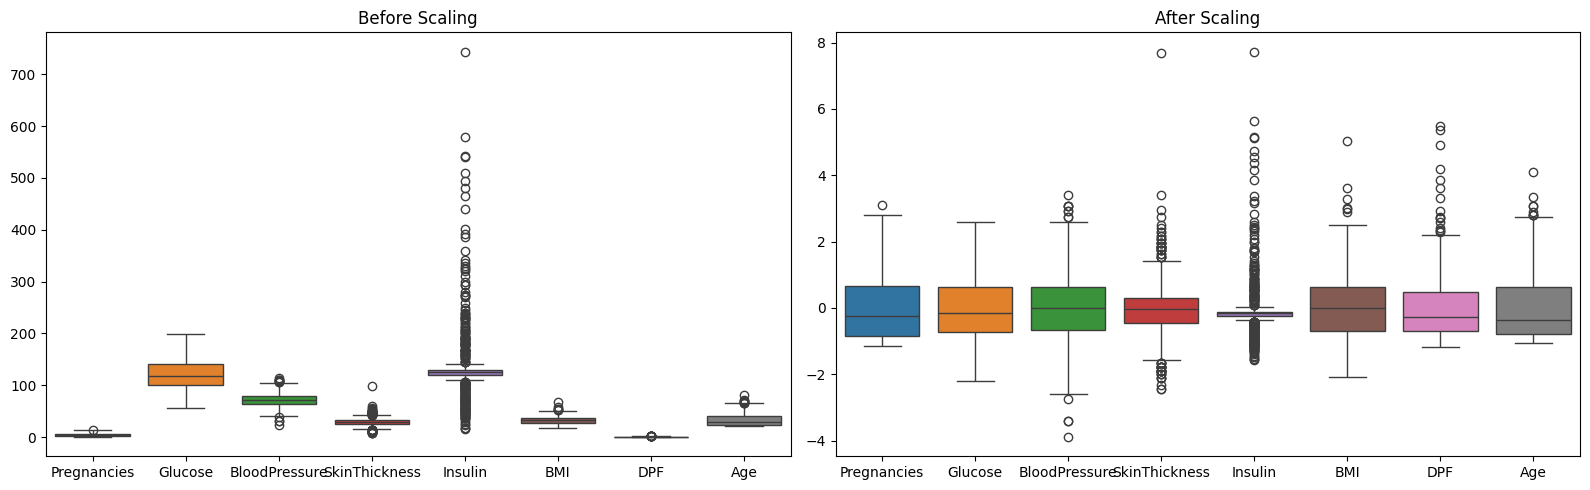

In [28]:
from sklearn import impute
X = df.drop("Outcome", axis=1)
y = df["Outcome"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 42, stratify = y)

X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, test_size = 0.2, random_state = 42, stratify = y_train)

imputer = SimpleImputer(strategy = "median")
X_train = imputer.fit_transform(X_train)
X_test = imputer.transform(X_test)
X_val = imputer.transform(X_val)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
X_val_scaled = scaler.transform(X_val)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

sns.boxplot(data = pd.DataFrame(X_train, columns = X.columns), ax = axes[0])
axes[0].set_title("Before Scaling")

sns.boxplot(data = pd.DataFrame(X_train_scaled, columns = X.columns), ax = axes[1])
axes[1].set_title("After Scaling")

plt.tight_layout()
plt.show()

